Case Study : Student Performance System

In [ ]:
#Create the Classroom dataset
#Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
students = pd.DataFrame({
    "student_id" : ["S01","S02","S03","S04","S05"],
    "course" : ["DA","PFS","DA","PFS","DA"],
    "hours" : [5,8,3,10,6],
    "score" : [55,70,40,85,65],
    "satisfaction" : ["Satisfied","Very Satisfied","Neutral","Satisfied","Very Satisfied"]
})
students

,student_id,course,hours,score,satisfaction
0,S01,DA,5,55,Satisfied
1,S02,PFS,8,70,Very Satisfied
2,S03,DA,3,40,Neutral
3,S04,PFS,10,85,Satisfied
4,S05,DA,6,65,Very Satisfied


In [ ]:
print("Shape:",students.shape)
print(type(students))
print(students.dtypes)
print(students.size)
print(students.ndim)
print(type(students.values))
print("Missing Values:",students.isna().sum())

Shape: (5, 5)
<class 'pandas.core.frame.DataFrame'>
student_id      object
course          object
hours            int64
score            int64
satisfaction    object
dtype: object
25
2
<class 'numpy.ndarray'>
Missing Values: student_id      0
course          0
hours           0
score           0
satisfaction    0
dtype: int64


In [ ]:
#Count Categories and Summarise Numerical Columns
print("Students per course count:",students['course'].value_counts())
print(students[['hours','score']].describe()) #Descriptive Stats information
#Observe Students Proportion
print((students['course'] == "DA").mean())
print((students['course'] == "PFS").mean())

Students per course count: course
DA     3
PFS    2
Name: count, dtype: int64
           hours      score
count   5.000000   5.000000
mean    6.400000  63.000000
std     2.701851  16.807736
min     3.000000  40.000000
25%     5.000000  55.000000
50%     6.000000  65.000000
75%     8.000000  70.000000
max    10.000000  85.000000
0.6
0.4


In [ ]:
#Python Central tendency and Interpretation
values = np.array([12,15,15,18,20,22,22,22,25,90])
mean_value = np.mean(values)
median_value = np.median(values)
mode_value = pd.Series(values).mode().tolist()
print("Mean:",mean_value)
print("Median",median_value)
print("Mode",mode_value)
print("Sorted Values",np.sort(values))

Mean: 26.1
Median 21.0
Mode [22]
Sorted Values [12 15 15 18 20 22 22 22 25 90]


In [ ]:
students.columns

Index(['student_id', 'course', 'hours', 'score', 'satisfaction'], dtype='object')

In [ ]:
#manual Calculation --> Sensitivity in the information -->Spread Outliers and Relationships
#Connect the library result to the manual calcn
values = np.array([12,15,15,18,20,22,22,22,25,90])
total = np.sum(values)
print(total)
count = len(values)
print(count)
manual_mean = total / count
print(f'Manual mean calculation result is {manual_mean}')
#manual Median calculation
ordered = np.sort(values)
print(ordered)
middle = count // 2  #10//2 --> 5
manual_median = (ordered[middle-1]+ordered[middle])/ 2 #Python indexing starts at 0
print("Manual Median:",manual_median)

261
10
Manual mean calculation result is 26.1
[12 15 15 18 20 22 22 22 25 90]
Manual Median: 21.0


In [ ]:
#Demonstrate the sensitivity to an extreme value
print(values)
#Exclude 90 only for a comparision,retaining the original array
comparision_values = values[values!=90]
comparision_values
print("Original Mean",np.mean(values))
print("Mean Excluding 90:",np.mean(comparision_values))
#Expected 26.1 and 19.0 --> The Boolean mask selects values that differ from 90,

[12 15 15 18 20 22 22 22 25 90]
Original Mean 26.1
Mean Excluding 90: 19.0


In [ ]:
#Python spread outliers and relationships
scores_a = np.array([58,60,62])
scores_b = np.array([20,60,100])
for name,scores in [("Akash",scores_a),("Sanjay",scores_b)]:
  print(name,scores)
  print(name,"Mean = ",np.mean(scores),
        "Range:",np.max(scores)-np.min(scores),
        "Population Std",round(np.std(scores),2))
  #Standard Deviation --> It quantifies the amount of variation or spread in a set of
  #data points relative to its mean
  #Low Standard Deviation --> Indicates that the datapoints tned to be very close to mean
  #High Standard Deviation  -->Indicates that the data points are spread over a wider range

Akash [58 60 62]
Akash Mean =  60.0 Range: 4 Population Std 1.63
Sanjay [ 20  60 100]
Sanjay Mean =  60.0 Range: 80 Population Std 32.66


In [ ]:
#Flag unusual values using the IQR (Inter Quartile Range)
print(values)
q1,q3 = np.percentile(values,[25,75])
print(q1)
print(q3)
iqr = q3 - q1  #Q1 -> Lower quartile,Q3 --> Upper Quartile
print(iqr)
lower = q1 - (1.5)*iqr
upper = q3 + (1.5)*iqr
print(lower)
print(upper)
flagged = values[(values < lower) | (values > upper)]
print("Q1:",q1,"Q3:",q3,"IQR:",iqr)
print("Fences:",lower,upper)
print("Flagged Value(s) [Outliers]:",flagged)

[12 15 15 18 20 22 22 22 25 90]
15.75
22.0
6.25
6.375
31.375
Q1: 15.75 Q3: 22.0 IQR: 6.25
Fences: 6.375 31.375
Flagged Value(s) [Outliers]: [90]


Pearson Correlation: 0.985


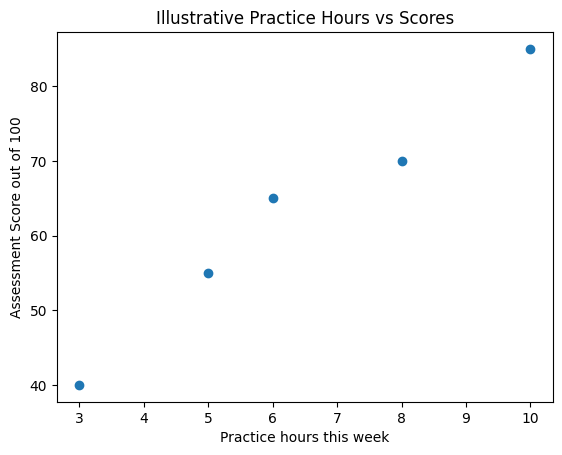

In [ ]:
#Exploring Numerical Relationship
import matplotlib.pyplot as plt
result = students["hours"].corr(students['score']) #Pearson Correlation
#Pearson Correlation (r) -->It is a statistcal measure that quantifies the
#strength and  direction of a linear relationship  between two continuous variables
#+1.0 --> Perfectly positive -->As variable x increases,y also increases in a perfect
#st.line
#-1.0 -->Perfectly negative --> As variable x increases,variable y decreases
#0.0 (No linear correlation) --> there is no linear relation b/w variables
result
print("Pearson Correlation:",round(result,3))
plt.scatter(students["hours"],students['score'])
plt.xlabel("Practice hours this week")
plt.ylabel("Assessment Score out of 100")
plt.title("Illustrative Practice Hours vs Scores")
plt.show()

In [ ]:
#Datatypes,Central Tendency and a First look at spread
#Variance,Standard Deviation,Quartiles and the IQR rule

#Range --> First measure of spread --> Range = Maximum - Minimum
#Student A --> Scores --> 58,60,62  --> Mean --> 60 --> Deviations --> -2,0,2
#Student B --> Scores --> 20,60,100 --> Mean -->60 --> Deviations -->-40,0,40
#For both students,the deviations add to zero.Averaged signed deviations would hide the
#spread.Squaring makes the contributions non negtaive and gives greater weight to larger
#deviations
#Scores -> A  --> Deviation as follows
'''
Score x        Mean.          Deviation (x-mean )         Squared Deviations
58              60              -2                       4
60.             60              0                        0
62              60               2                        4

Total Sqd deviation = 4 + 0 + 4 = 8 --> Population variance = 8 / 3 = 2.667 marks squared
Population Variance = Sum of Squared Deviations / N
Population Standatd deviation =  Square root[Summation (xi - u)**2] / N #xi --> each individual value
u --> population mean
Population Std Deviation  --> Sqrt(2.667) --> 1.663 marks
'''
print(scores_a)
print(scores_b)
mean_a = np.mean(scores_a)
print(mean_a)
deviations = scores_a - mean_a
print(deviations)
squared_deviations = deviations**2
squared_total = np.sum(squared_deviations)
print(squared_total)
variance_a = squared_total / len(scores_a)
print(variance_a)
std_a = np.sqrt(variance_a)
print(std_a)

[58 60 62]
[ 20  60 100]
60.0
[-2.  0.  2.]
8.0
2.6666666666666665
1.632993161855452


In [ ]:
#Comparing both scores and both denominators
for name,scores in [("A",scores_a),('B',scores_b)]:
  print(name,"range",np.ptp(scores),
        "Pop Std",np.std(scores),
        "Sample Std",np.std(scores,ddof=1))

A range 4 Pop Std 1.632993161855452 Sample Std 2.0
B range 80 Pop Std 32.65986323710904 Sample Std 40.0


In [ ]:
#Quartiles IQR and Outlier Screening
#values
q1,median,q3 = np.percentile(values,
                             [25,50,75],
                             method="linear")
print(q1)
print(q3)
print("Median:",median)
iqr = q3 - q1
print("Inter Quartile Range:",iqr)
lower_fence = q1 - 1.5*iqr
upper_fence = q3 + 1.5*iqr
outlier_mask = ((values < lower_fence) | (values > upper_fence))
print("Flagged Values:",values[outlier_mask].tolist())

15.75
22.0
Median: 21.0
Inter Quartile Range: 6.25
Flagged Values: [90]


In [ ]:
#Preserve the observations with review labels
review = pd.DataFrame({
    "Observations_Id" : np.arange(1,len(values)+1),
    "Value":values,
    "IQR_Flag":outlier_mask
})
review

,Observations_Id,Value,IQR_Flag
0,1,12,False
1,2,15,False
2,3,15,False
3,4,18,False
4,5,20,False
5,6,22,False
6,7,22,False
7,8,22,False
8,9,25,False
9,10,90,True


In [ ]:
d=review.to_string(index=False)
print(d)
print(type(d))

 Observations_Id  Value  IQR_Flag
               1     12     False
               2     15     False
               3     15     False
               4     18     False
               5     20     False
               6     22     False
               7     22     False
               8     22     False
               9     25     False
              10     90      True
<class 'str'>


In [ ]:
review

,Observations_Id,Value,IQR_Flag
0,1,12,False
1,2,15,False
2,3,15,False
3,4,18,False
4,5,20,False
5,6,22,False
6,7,22,False
7,8,22,False
8,9,25,False
9,10,90,True


In [ ]:
print("Flagged IDs",review.loc[review["IQR_Flag"],
                               "Observations_Id"].tolist())

Flagged IDs [10]


In [ ]:
print(lower_fence)
print(upper_fence)
print(q1,median,q3)

6.375
31.375
15.75 21.0 22.0


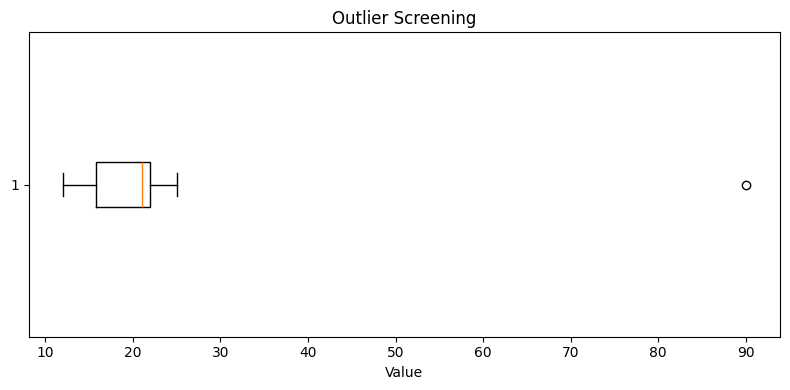

In [ ]:
#Python Box and Whisker Plot
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize= (8,4))
ax.boxplot(values,vert=False,whis=2.5)
ax.set_xlabel("Value")
ax.set_title("Outlier Screening")
fig.tight_layout()
plt.show()
#Expecting a box from 15.75 to 22 a median at 21,and separate marker at 90 which indicates
#outlier,with whiskers pointing at 6.375 and upper_fence at 31.375

In [ ]:
#Explain Sensitivity without deleting data
comparision = values[~outlier_mask]
print(comparision)
print("All Mean",np.mean(values))
print("Comparision Mean",np.mean(comparision))
print("All Median",np.median(values))
print("Comparision Median",np.median(comparision))
#Comparision is only used to demonstrate the sensitivity;values and refview still preserve
#the original records

[12 15 15 18 20 22 22 22 25]
All Mean 26.1
Comparision Mean 19.0
All Median 21.0
Comparision Median 20.0


Signed Deviations cancel and Squared Deviations reveal spread
Variance uses Squared units,STD used Original units
IQR fences and Box and whsiker plot endpoints are important
Outlier detection creates a review flag,not a deletion instruction

In [ ]:
#Positive and Negative Covariance using Paired deviations
#Pearson Correlation from Covariance and Std devaitions
#Linear Association from Monotonic Association and Causation
#Python to verify the calculations and inspect scatter plots
students

,student_id,course,hours,score,satisfaction
0,S01,DA,5,55,Satisfied
1,S02,PFS,8,70,Very Satisfied
2,S03,DA,3,40,Neutral
3,S04,PFS,10,85,Satisfied
4,S05,DA,6,65,Very Satisfied


In [ ]:
#create a new observation table
data = pd.DataFrame({
  'Observation':np.arange(1,7),
  'Practice_Hours':[2,4,5,7,8,10],
  'Assessment Score':[35,48,55,68,74,90]
})
data

,Observation,Practice_Hours,Assessment Score
0,1,2,35
1,2,4,48
2,3,5,55
3,4,7,68
4,5,8,74
5,6,10,90


In [ ]:
#Variance --> multiplies a variables deviation by itself.
#CoVariance --> multiplies the deviation in X by the paired deviation in Y.
'''
X deviation          Y deviation            Product      Contribution
Positive.             Positive               Positive.      Both above their means
Negative              Negative.              Positive       Both below their means
Positive.             Negative               Negative       Opposite sides of their means
Negative              Positive.             Negative.       Opposite sides of their means

Population Covariance = Sum of (xi - population mean of X) * (yi - population mean of Y)
                     ------------------------------------------------------------------
                                  N
Sample Covariance = Sum of (xi - sample mean of X) * (yi-sample mean of Y) / n-1

xi and yi are paired values,N is population size,n is the sample size
'''
data[['Practice_Hours','Assessment Score']]
#x - mean x (Hours --> x) (mean_x --> x)
#x1 --> x1 - meanx --> 2 - 6 --> -4
#x2 --->4-6 --> -2
#x3 -->5-6 --> -1
#x4 --> 1
#x5 --> 2
#x6 --> 4
#y- mean_y --> (Scores -->y) --> mean_y --> 61.67
#y1 --> -26.67
#y2 --> -13.67
#y3 --> -6.67
#y4 --> 6.33
#y5 --> 12.333
#y6 --> 28.33
#product --> x1*y1 ->106.67
#x2*y2 -->27.33
#x3*y3 -->6.67
#x4*y4 -->6.33 x5*y5 -->24.67.  x6*y6 -->113.33
#sum of deviation products = 285. --> Population cov = 285 / 6 -->47.5.
#sample covariance = 285 / 5 -> 57
#Both are positive,indication is more hours --> higher score

,Practice_Hours,Assessment Score
0,2,35
1,4,48
2,5,55
3,7,68
4,8,74
5,10,90


In [ ]:
#Python Covariance
hours = np.array([2,4,5,7,8,10],dtype=float)
#hours
scores = np.array([35,48,55,68,74,90],dtype=float)
data = pd.DataFrame({"Hours":hours,'Scores':scores})
print(data)
print("Shape is:",data.shape)
print("Missing Values:",data.isna().sum().to_dict())
#Cal covariance from deviations
#We will create the variables as per formula
n = len(hours)
dx = hours - np.mean(hours)
print(dx)
dy = scores - np.mean(scores)
print(dy)
products = dx*dy
print(products)
cross_total = np.sum(products)
pop_cov = cross_total / n
sample_cov = cross_total / (n-1)
print("Product Total",cross_total)
print("Population Covariance",pop_cov)
print("Sample Covariance",sample_cov)

   Hours  Scores
0    2.0    35.0
1    4.0    48.0
2    5.0    55.0
3    7.0    68.0
4    8.0    74.0
5   10.0    90.0
Shape is: (6, 2)
Missing Values: {'Hours': 0, 'Scores': 0}
[-4. -2. -1.  1.  2.  4.]
[-26.66666667 -13.66666667  -6.66666667   6.33333333  12.33333333
  28.33333333]
[106.66666667  27.33333333   6.66666667   6.33333333  24.66666667
 113.33333333]
Product Total 285.0
Population Covariance 47.5
Sample Covariance 57.0


Why Standardise Covariance -->
A Covariance changes in above case if hours are expressed in minutes..


Correlation divides the Covariance by Standard Deviations of both variables so that the units cancel and mainly values lies b/w -1 and +1,provided both variables have nonzero variation
Sample Pearson Correlation =
(r) = Sample Covariance (X,Y) / (Sample Std Deviation of X * Sample Std Deviation of Y)...

for above observations,sample variance of hours --> Summation (xi - mean_x)**2 / n-1
--> (2-6)**2 + (4-6)**2 + (5-6)**2 + (7-6)**2 + (8-6)**2 + (10-6)**2 / 5
-->16 + 4 + 1 + 1 + 4 + 16 / 5 -> 8.4

Sample Std Deviation --> Sqrt(Sample Variance). --> 2.89

Sample variance of scores -> 387.466
Sample Std Deviation --> 19.6

Sample Pearson Correlation(r) = 57 /(2.89 *19.6)  --> ~1 This describes a very strong positive linear association in given 6 observations...

Covariance comapred with correlation
Property.     Covaraince.           Pearson Correlation
-->Units        Product of two units.  unitless
-->Range.       No fixed bounds.      -1 to +1 defined
-->Positive unit rescaling changes magnitude unchanged
--> Purpose.     Describes Joint variation.  Describe linear association (direction and strength)

#A negative rescaling reverses the correlation sign.Adding a constant to either variable leaves Pearson Correlation unchanged..

In [ ]:
#Verify and Standardise
cov_matrix = np.cov(hours,scores,ddof=1)
print(cov_matrix)
r_manual = sample_cov / (np.std(hours,ddof=1)*(np.std(scores,ddof=1)))
r = np.corrcoef(hours,scores)[0,1]
print(f'Manual r is {round(r_manual,4)}')
print(f'Using Numpy value of r is {round(r,4)}')

[[  8.4         57.        ]
 [ 57.         387.46666667]]
Manual r is 0.9991
Using Numpy value of r is 0.9991


In [ ]:
#Ranks adn Careful Analytical conclusions
#Pearson and Spearman
#Pearson measures linear association between numerical variables
#Spearman is Pearson Correlation of the ranks and measures monotonic association;whther the values are
#consistently tend to increase together or move in opposite...
#Montonic --> It is a trend where two variables move in a concise relative direction,but not
#necessarily at a constant rate...
#Linear -->Perfect St.line
#Monotonic -->can be straight line or a  curve that never reverses direction

#For x = [1,2,3,4,5], y = [1,4,9,16,25] both rank lists --> [1,2,3,4,5],
#Spearman Correlation -->1
#Pearson Correlation --> 0.99
#pandas --> rank() assigns average ranks by default

In [ ]:
#Python unit changes ranks and edge cases
minutes = hours * 60
print(minutes)
cov_minutes = np.cov(minutes,scores)[0,1]
print(cov_minutes)
r_minutes = np.corrcoef(minutes,scores)
print(r_minutes)
print("Pandas Correlation:",data.corr())
#We have receieved Expected Covaraince as 3420 minutes * marks --> Correlation is making
#same value around 0.9991

#Cal Spearman through ranks
x_rank_demo = pd.Series([1,2,3,4,5])
y_rank_demo = pd.Series([1,4,9,16,25])
pearson_demo = x_rank_demo.corr(y_rank_demo)
print(pearson_demo)
x_ranks = x_rank_demo.rank()
print("X ranks",x_ranks)
y_ranks = y_rank_demo.rank()
print("Y ranks",y_ranks)
print("Spearman:",round(x_ranks.corr(y_ranks),4))

[120. 240. 300. 420. 480. 600.]
3420.0
[[1.         0.99912089]
 [0.99912089 1.        ]]
Pandas Correlation:            Hours    Scores
Hours   1.000000  0.999121
Scores  0.999121  1.000000
0.981104910251593
X ranks 0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
dtype: float64
Y ranks 0    1.0
1    2.0
2    3.0
3    4.0
4    5.0
dtype: float64
Spearman: 1.0


[-2. -1.  0.  1.  2.]
[4. 1. 0. 1. 4.]
0.0


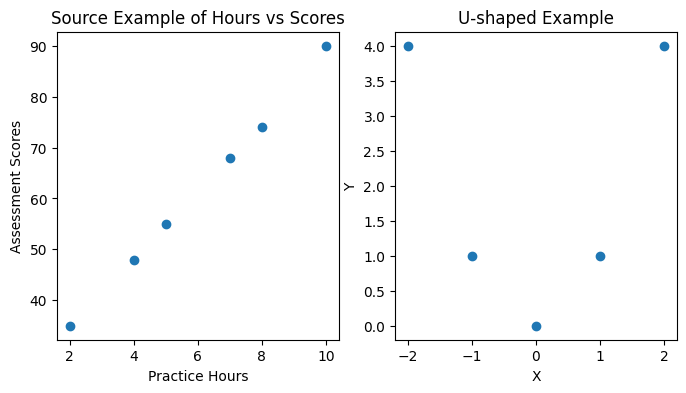

In [ ]:
#Python Scatter plots and nonlinear plots
#Compare a line-like pattern with curve
curve_x = np.array([-2,-1,0,1,2],dtype=float)
curve_y = curve_x**2
print(curve_x)
print(curve_y)
curve_r = np.corrcoef(curve_x,curve_y)[0,1]
print(curve_r) #indicates that complete absence of linear or montonic relationship
#display the plot for above mentioned data
fig,axes = plt.subplots(1,2,figsize=(8,4))
axes[0].scatter(hours,scores)
axes[0].set(xlabel="Practice Hours",
            ylabel ="Assessment Scores",title="Source Example of Hours vs Scores")
axes[1].scatter(curve_x,curve_y)
axes[1].set(xlabel="X",ylabel="Y",title="U-shaped Example")
plt.show()

Probability Distributions -->

It describes the possible values of a random variable and how does probability is assigned to them..
It connects uncertainity to the mean,variance and standard deviation which we have discussed.

Random Experiment --> It has an outcome that is not known with certainity in advance.A random variable will assign a numerical value to each outcome...we use X for variable..

x or k denotes for possible result

For one Assessment let X = 1 (Pass),X=0 otherwise --> Let Y be number of passess..
Let T be time completion in minutes..

Discrete      ---> A finite or countability infinite set        0,1,2,3,,,,,,,,, calls in a minute

Continuous    --> Any value in a continuous interval.   --> task duration in minutes

Observed Frequency describe a dataset..

Probability model will describe a proposed mechanism that generates observations...

Eg: 6 passess out of 10 attempts --> Proportion -->6 / 10 --> 0.6
A small dataset will not establish exact probability for every future dataset.

PMF ,PDF , CDF -->
PMF --> Probability Mass Function
--> it gives the exact probability that a discrete random variable equals to a specific value

p(x) = P(X=x)

-->Every probability outcome must be between
0 and 1
-->The sum of all proababilities across all
possible values equal to 1

--> Rolling a 3 on fair six sided die
P(X=3) = 1 / 6


PDF --> Probability Density Function

--> It describes the probability density (likelihood per unit length) of a continuous random variable..(measures like height,weight,time...)
 --> Probability of a cont.variable taking one exact single point always P(X=x) = 0
 -->It is calculated by area under the curve..
 --> Person's height falling between 160cms to 180 cms by integrating PDF over that range..


CDF --> Cumulative Density Function
-->It describes the cumulative probability that a random variable is less than or equal to given value (x) --> F(x) = P(X<=x)

-->Can be applied for both discrete and continuous CDF values 0 and 1
-->Discrete variables --> It forms a step function
-->Continuous variables -->It is a smooth,S shaped curve

P(X=4) = 1 / 6 and P(X<=4) = 4 / 6


In [ ]:
import numpy as np
#!pip install scipy
from scipy import stats
import matplotlib.pyplot as plt

In [ ]:
#Bernoulli Distribution --> It models one trial with two possible outcomes
#1 for Success,0 for Failure
#P(X=x) = p^x(1-p)^1-x,  x E {0,1}
#p -->Probability of X=1; 0<=p<=1
#Support --> 0 and 1
#Mean -->p;Variance --> p(1-p);Std --> Sqrt(p(1-p))

p = 0.6 #model assigns probability to pass one assessment
pass_prob = stats.bernoulli.pmf(1,p)
fail_prob = stats.bernoulli.pmf(0,p)
bernoulli_mean = p
bernoulli_var = p*(1-p)
print(f'Pass:',round(pass_prob,4))
print(f'Fail:',round(fail_prob,4))
print(f'Mean:',bernoulli_mean)
print("Variance:",bernoulli_var)
print("Standard Deviation:",round(np.sqrt(bernoulli_var),4))
#p sets the success probability,pass_prob and fail_prob --> exact probabilites
#bernoulli_var describes the therotical variance..

Pass: 0.6
Fail: 0.4
Mean: 0.6
Variance: 0.24
Standard Deviation: 0.4899


Binomial Distribution:
Connection to binary data --> Yes/no --> Bernoulli

Counting how many yes outcomes across a fixed set of independent trials with the same
probability leads to Binomial distribution.

A Binomial variable counts successes in a fixed number n of independent Bernoulli trails with the same success probability p..

P(X=k) = (nk)p^k(1-p)n-k
Binomial Coefficient C(n,k) = n!/([k!(n-k)!])
counts the arrangements of k successes among n trials..
Mean =np,Variance = np(1-p),Std = sqrt(np(1-p))


In [ ]:
#Assume five independent assessments,each with probabilty 0.6.Let X be the total passes.
#For exactly three passes; n = 5,k=3,p =0.6
#There are C(5,3) = 5! / 3!*2! --> 10
#One part.sequence with three passes and two failures has probability
#0.6 ** 3 * 0.4 **2 --> 0.03456..Therefore P(X=3) = 10*0.03456 --> 0.3456
#Mean = 5*0.6 -> 3 passes
#Variance = np(1-p) -> 3 *(1-0.6) -> 3 * 0.4 --> 1.2
#Std --> 1.09


In [ ]:
#Letus link above scenario to our Python example with exact and cumulative probabilities
n,p = 5,0.6 #n --> fixed trail count,
#p is the probability per trail pmf(3) only three passes.cdf(3) --> probabilities
#for 0 through 3,sf(2) --> adds probabilities for 3 through 5
exact_three = stats.binom.pmf(3,n,p)
print(f'PMF P(X=3) --> {exact_three}')
at_most_three = stats.binom.cdf(3,n,p)
print(f'Atmost Three--> {round(at_most_three,4)}')
at_least_three = stats.binom.sf(2,n,p)
print(f'Atleast Three --> {round(at_least_three,5)}')

PMF P(X=3) --> 0.3455999999999997
Atmost Three--> 0.663
Atleast Three --> 0.68256


The result is conditional on the model assumptions.Repeated Assessments of the same person may have dependence or different difficulty..In that case,a common independent trial binomial model is suitable


Poisson Distribution --> A Poisson Variable models the number of events in a fixed time,area,distance or a volume.

It processes the events which occur with independent increments and a constant rate..
The count has no fixed upper limit

P(X=k) = (Lambda^k)(exponential -lambda) /k! , k = 0,1,2.....

Lambda --> expected number of events in the specified interval.it must be non negative..
Mean = Lambda,Variance = Lambda...
If the rate is r events per time unit over t units
lambda = r * t

Assume a Support Desk receives calls according to Poisson process with rate 3 calls per minute..
Over one minute = lambda = 3

For exactly 2 calls P(X=2) e^-3*3^2 / 2!
--> 0.2240

For atleast one call,use the complement
P(X>=1) = 1 - P(X=0) = 1 - e^-3(1) -> 0.95

#Over two minutes the expected count becomes 6 not 3

In [ ]:
lam = 3 #from above scenario
exact_two = stats.poisson.pmf(2,lam)
print(f"Exact two: {exact_two}")
atleast_one = stats.poisson.sf(0,lam)
print(f"Atleast one: {atleast_one}")
atleast_five = stats.poisson.sf(4,mu=lam)
print(f"Atleast Five: {atleast_five}")
print("Two Minute mean:",lam*2)
print("Mean:",lam,"Variance",lam)
#Variable roles -->lam stores the expected count per one minute interval..
#Scipy use parameter mu --> lam ->Atleast five cases which includes -->5,6,7 and above...

Exact two: 0.22404180765538775
Atleast one: 0.950212931632136
Atleast Five: 0.18473675547622787
Two Minute mean: 6
Mean: 3 Variance 3


#Continuous Distributions --> Normal Distribution,Uniform Distribution..

Assessment Scores are approx by mean and how the values are distributed --> Standard Deviation..
It is a continous,symmetric bell shaped curve Its mean mu sets the centre and the positive std deviation...

Z- score = x - u(mean) / std deviation

Variance is sigma squared...

In [ ]:
#mean,median and mode --> mu
#Variance is sigma squared
mu = 60;sigma = 10
from scipy import stats
hours = np.array([2,4,5,7,8,10],dtype=float)
#hours
scores = np.array([35,48,55,68,74,90],dtype=float)
data = pd.DataFrame({"Hours":hours,'Scores':scores})
print(data)

   Hours  Scores
0    2.0    35.0
1    4.0    48.0
2    5.0    55.0
3    7.0    68.0
4    8.0    74.0
5   10.0    90.0


In [ ]:
(90+74+35+48+55+68) / 6

61.666666666666664

In [ ]:
# To locate a score 70 with the interval from 50 to 70
mu = 60;sigma = 10
within_one = stats.norm.cdf(70,loc=mu,scale=sigma) - stats.norm.cdf(50,loc=mu,
                                                                    scale=sigma)
print(f'Between 50 and 70 {within_one}') #if we keep the values nearer to 70 it reaches to 0
#Probability of the values within P(50<X<70) = F(70) - F(50) --> 0.682 = 68.27%
print('Between 50 and 70:',round(within_one,4)*100)
Z_Score = (70 - 60) / 10
print(Z_Score) #it lies one standard deviation above mean
above_seventy = stats.norm.sf(70,loc=mu,scale=sigma)
print(f'Above 70 {above_seventy}')
percentile_90 = stats.norm.ppf(0.90,loc=mu,scale=sigma)
print(f'90th Percentile {percentile_90}')
#As in this case Scores are bounded in practice,so noramlity is an approximation

Between 50 and 70 0.6826894921370859
Between 50 and 70: 68.27
1.0
Above 70 0.15865525393145707
90th Percentile 72.815515655446


In [ ]:
# To locate a score 70 with the interval from 50 to 70
mu = 40;sigma = 10
within_one = stats.norm.cdf(70,loc=mu,scale=sigma) - stats.norm.cdf(50,loc=mu,
                                                                    scale=sigma)
print(f'Between 50 and 70 {within_one}') #if we keep the values nearer to 70 it reaches to 0
#Probability of the values within P(50<X<70) = F(70) - F(50) --> 0.682 = 68.27%
print('Between 50 and 70:',round(within_one,4)*100)
Z_Score = (70 - 40) / 10
print(Z_Score) #it lies one standard deviation above mean
above_seventy = stats.norm.sf(70,loc=mu,scale=sigma)
print(f'Above 70 {above_seventy}')
percentile_90 = stats.norm.ppf(0.90,loc=mu,scale=sigma)
print(f'90th Percentile {percentile_90}')
#As in this case Scores are bounded in practice,so noramlity is an approximation

Between 50 and 70 0.15730535589982697
Between 50 and 70: 15.73
3.0
Above 70 0.0013498980316300933
90th Percentile 52.815515655446006


In [ ]:
# To locate a score 70 with the interval from 50 to 70
mu = 70;sigma = 10
within_one = stats.norm.cdf(70,loc=mu,scale=sigma) - stats.norm.cdf(50,loc=mu,
                                                                    scale=sigma)
print(f'Between 50 and 70 {within_one}') #if we keep the values nearer to 70 it reaches to 0
#Probability of the values within P(50<X<70) = F(70) - F(50) --> 0.682 = 68.27%
print('Between 50 and 70:',round(within_one,4)*100)
Z_Score = (70 - 70) / 10
print(Z_Score) #it lies one standard deviation above mean
above_seventy = stats.norm.sf(70,loc=mu,scale=sigma)
print(f'Above 70 {above_seventy}')
percentile_90 = stats.norm.ppf(0.90,loc=mu,scale=sigma)
print(f'90th Percentile {percentile_90}')
#As in this case Scores are bounded in practice,so noramlity is an approximation

Between 50 and 70 0.4772498680518208
Between 50 and 70: 47.72
0.0
Above 70 0.5
90th Percentile 82.815515655446


Continuous Uniform Distributions -->It has a constant density bounds a and b where b > a,and zero density outside them

F(X) = 1 / b -a   (a<=x<=b)

Suppose a duration modelled uniform between
10 and 20 minutes the density => 1 / (20-10)
= 1/10 --> 0.1 per minute
Mean = (a+b)/2 -> (10+20)/2 --> 15 minutes
variance = (b-a)^2 / 12 for interval [c,d]

fully inside [a,b].  --> 12 to 16 minutes

Variance = 100/12 --> 8.34

In [ ]:
a,b = 10,20 # a and b are lower and upper bounds
loc = a
scale = b - a
interval_prob = stats.uniform.cdf(16,loc=loc,scale=scale) - stats.uniform.cdf(12,loc=loc,
                                                                              scale=scale)
print(interval_prob)
print("Between 12 and 16:",round(interval_prob,4)*100)
density_at_15 = stats.uniform.pdf(15,loc=loc,scale=scale)
print("Density at 15",density_at_15)
print("Mean",(a+b)/2)
print("Variance",((b-a)**2)/12)

0.39999999999999997
Between 12 and 16: 40.0
Density at 15 0.1
Mean 15.0
Variance 8.333333333333334


[2 3 2 ... 4 3 3]
10000
[0.0114 0.0748 0.2254 0.3472 0.263  0.0782]
[0.01024 0.0768  0.2304  0.3456  0.2592  0.07776]


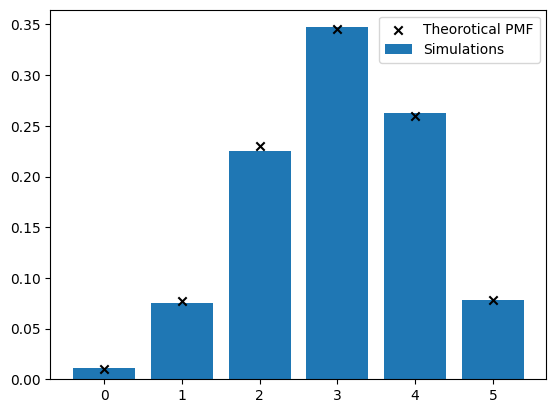

In [ ]:
#Simulation and Empirical probability
#Simulation generates observations from an assumed model
#10,000 groups containing five independent trials p =0.6 Each element is a total betweem
#0 and 5
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
sample = rng.binomial(n=5,p=0.6,size=10000)
print(sample)
print(len(sample))
k = np.arange(6)
counts = np.bincount(sample,minlength=6)
empirical = counts / len(sample)
print(empirical)
therotical = stats.binom.pmf(k,n=5,p=0.6)
print(therotical)
plt.bar(k,empirical,label="Simulations")
plt.scatter(k,therotical,marker="x",color="black",label="Theorotical PMF")
plt.legend()
plt.show()

Sampling Techniques and Central Limit Theorem

Population --> Group of interest
Sample --> Subset actually examined
Population Size --> N
Sample size --> n
Census --> Collect data from every member

Mean --> mu

In [ ]:
Population = [40,50,60,70,80]
Population_mean = sum(Population)/len(Population)
print(Population_mean)

60.0


In [ ]:
import numpy as np
Population = np.array([40,50,60,70,80])
Population_mean = np.sum(Population)/len(Population)
print(Population_mean)

60.0


In [ ]:
#Sample A --> 40,50   --> Sample Mean A --> 40+50/2 --> 45 --> Error 45 - 60 = -15
#Sample B --> 50,70   --> Sample Mean B --> 50+70/2 --> 60 --> 0
#Sample C --> 70,80   --> Sample Mean C --> 70+80/2 --> 75 -->Error = 75-60 =15
#Sampling Variation -->

#Simple Random Sampling;Systematic Sampling
#Simple Random Sampling
import random
students = list(range(1,1001))
print(students)
print(len(students))
#we want to set a seed value
random.seed(42) #we can take any value but this has given better interpretations
selected_students = random.sample(students,100)
print(selected_students)
print(len(selected_students))

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 22

In [ ]:
print("First 5 IDs",selected_students[:5])

First 5 IDs [655, 115, 26, 760, 282]


In [ ]:
#Systematic sampling
#Choose a random starting point,then select every kth member..
#if N=1000,n=100 and interval k = N/n = 10
#Starting ID 27 --> 27,37,47,57.....
interval = 10
random.seed(42)
start_index = random.randrange(interval)
print(start_index)
selected_students = students[start_index::interval]
print(selected_students[:])

1
[2, 12, 22, 32, 42, 52, 62, 72, 82, 92, 102, 112, 122, 132, 142, 152, 162, 172, 182, 192, 202, 212, 222, 232, 242, 252, 262, 272, 282, 292, 302, 312, 322, 332, 342, 352, 362, 372, 382, 392, 402, 412, 422, 432, 442, 452, 462, 472, 482, 492, 502, 512, 522, 532, 542, 552, 562, 572, 582, 592, 602, 612, 622, 632, 642, 652, 662, 672, 682, 692, 702, 712, 722, 732, 742, 752, 762, 772, 782, 792, 802, 812, 822, 832, 842, 852, 862, 872, 882, 892, 902, 912, 922, 932, 942, 952, 962, 972, 982, 992]


In [ ]:
print("First Selected ID:",selected_students[0])
print("Selected Count:",len(selected_students))

First Selected ID: 2
Selected Count: 100


Rememember : Periodic patterns in the list can cause problems..If every tenth record belogns to same subgroup (sample)then every tenth selection may misrepresent the popuation.But in above case we have used exact interger interval

In [ ]:
#Stratified Sampling --> Divide the population into meaningful,non-overlapping groups
#called strata..Randomly sample from every stratum..
#Popualtion 1000
#DA   --> 600    --> 60%.    --> 60
#PFS  --> 400    --> 40 %.   --> 40
#Group sample size = (group population / total population) * n
da_students = list(range(1,601))
pfs_students = list(range(601,1001))
random.seed(42)
da_sample = random.sample(da_students,60)
pfs_sample = random.sample(pfs_students,40)
print(da_students)
print(len(da_sample))
print(len(pfs_sample))
print(da_sample[0])
print(pfs_sample[0])
selected_students = da_sample + pfs_sample
print(selected_students)
print(len(selected_students))
#Unequal sampling fractions are also possible..They may require weights(strong criteria)

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 22

In [ ]:
#Cluster Sampling -->Divide the population into natural groups,randomly select some groups
 #for ex --> 4 out of 20 batches randomly and we start surverying student in those
 #4 batches..
 #Stratified --> Every Stratum contribute.   --> represent imp subgroups
 #Cluster --> Some randomly selected clusters. --> data collction practical

 #Convenience Sampling --> It is quick,but conclusions about wider population need care.